In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.preprocessing import MinMaxScaler
import seaborn as sns

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/drug200.csv')
df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,DrugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,DrugY


1. Data Understanding

In [ ]:
print("data shape : ", df.shape)

data shape :  (200, 6)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    object 
 2   BP           200 non-null    object 
 3   Cholesterol  200 non-null    object 
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.5+ KB


In [ ]:
df.describe()

,Age,Na_to_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


In [ ]:
df.Drug.value_counts()

,count
Drug,
DrugY,91
drugX,54
drugA,23
drugC,16
drugB,16


In [ ]:
df.Sex.value_counts()

,count
Sex,
M,104
F,96


<Axes: xlabel='Age', ylabel='Count'>

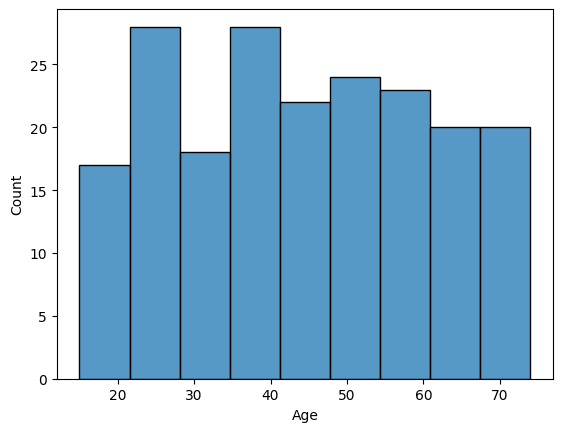

In [ ]:
sns.histplot(df['Age'])

2. Cleaning Data


In [ ]:
df.isnull().sum()

,0
Age,0
Sex,0
BP,0
Cholesterol,0
Na_to_K,0
Drug,0


In [ ]:
df.duplicated().sum()

np.int64(0)

3. EDA

/tmp/ipykernel_550/4020790831.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Drug', data=df, palette='flare')


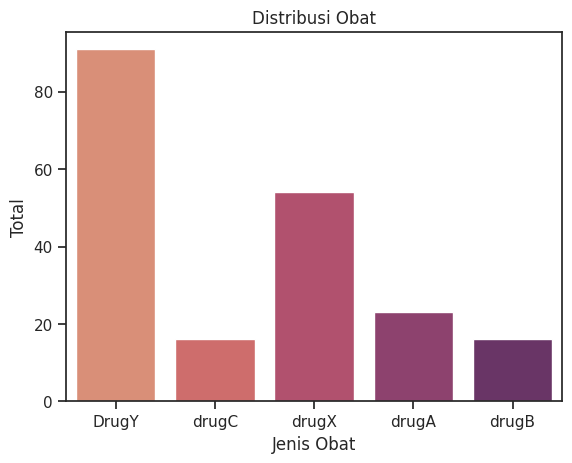

In [ ]:
sns.set_theme(style="ticks")
sns.countplot(x='Drug', data=df, palette='flare')
plt.ylabel('Total')
plt.xlabel('Jenis Obat')
plt.title('Distribusi Obat')
plt.show()

/tmp/ipykernel_550/2075656758.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Sex', data=df, palette='rocket')


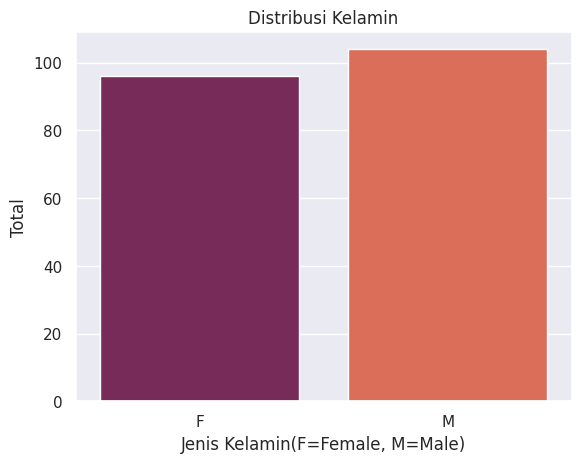

In [ ]:
sns.set_theme(style="darkgrid")
sns.countplot(x='Sex', data=df, palette='rocket')
plt.ylabel('Total')
plt.xlabel('Jenis Kelamin(F=Female, M=Male)')
plt.title('Distribusi Kelamin')
plt.show()

4. Data Preparation

In [ ]:
#Mengubah atribut string jadi integer dengan encoding/labeling
from sklearn.preprocessing import LabelEncoder
lebel_encoder = LabelEncoder()
df['Sex'] = lebel_encoder.fit_transform(df['Sex'])
df['BP'] = lebel_encoder.fit_transform(df['BP'])
df['Cholesterol'] = lebel_encoder.fit_transform(df['Cholesterol'])
df['Drug'] = lebel_encoder.fit_transform(df['Drug'])
df.head()


,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,0,0,0,25.355,0
1,47,1,1,0,13.093,3
2,47,1,1,0,10.114,3
3,28,0,2,0,7.798,4
4,61,0,1,0,18.043,0


In [ ]:
#spliting data
x = df.drop(columns=['Drug'])
y = df['Drug']
print('X : ', x.shape)
print('Y : ', y.shape)

X :  (200, 5)
Y :  (200,)


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
print(f"x_train : {x_train.shape}")
print(f"x_test : {x_test.shape}")
print(f"y_train : {y_train.shape}")
print(f"y_test : {y_test.shape}")

x_train : (160, 5)
x_test : (40, 5)
y_train : (160,)
y_test : (40,)


5. Scaling

In [ ]:
# Inisialisasi scaler
scaler = MinMaxScaler()

# Fit dan transform pada data training, dan transform pada data testing
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

6. Modeling

In [36]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(x_train_scaled, y_train)
y_pred = knn.predict(x_test_scaled)
KNN_acc = accuracy_score(y_test, y_pred)
print(classification_report(y_test, y_pred))
print('Accuracy KNN: {:.2f}%'.format(KNN_acc*100))

              precision    recall  f1-score   support

           0       0.82      0.93      0.88        15
           1       1.00      0.83      0.91         6
           2       1.00      1.00      1.00         3
           3       1.00      1.00      1.00         5
           4       0.90      0.82      0.86        11

    accuracy                           0.90        40
   macro avg       0.94      0.92      0.93        40
weighted avg       0.91      0.90      0.90        40

Accuracy KNN: 90.00%


7. Testing

In [ ]:
testing = {'Age': [40],
           'Sex': [1],
           'BP': [1],
           'Cholesterol': [0],
           'Na_to_K': [4.0]}

testing = pd.DataFrame(testing)
testing

,Age,Sex,BP,Cholesterol,Na_to_K
0,40,1,1,0,4.0


In [37]:
# Lakukan penskalaan pada data testing baru
testing = scaler.transform(testing)

pred_coba = knn.predict(testing)
pred_coba = lebel_encoder.inverse_transform(pred_coba)
print("Hasil presiksi dari data pasien baru:")
print(pred_coba[0])

Hasil presiksi dari data pasien baru:
drugC
